### Prof. Alfio Ferrara

# Embedding in un mondo piccolo

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nei notebook precedenti i vettori delle parole sono comparsi in due modi: appresi per prevedere un'etichetta (il clima di una città) e appresi per indovinare una parola dal suo contesto. Qui li mettiamo a confronto in un mondo così piccolo che possiamo guardare tutto: ogni frase, ogni parola, ogni parametro.

Nella seconda parte teniamo fisso il modello e cambiamo i dati: quanti sono, di che cosa parlano, e come cambia una parola quando cambia il modo in cui viene usata.

## Un mondo piccolissimo

Il mondo ha quattro domini: animali, cucina, informatica, pesca. Ogni frase ha tre parole, un soggetto, un verbo e un oggetto dello stesso dominio, scelti a caso. Il vocabolario ha 52 parole. Non c'è altro: niente articoli, niente punteggiatura, nessun significato che non si possa ricavare dalle frasi.

La parola *rete* per ora compare solo nelle frasi di pesca.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import linkage, leaves_list

world = {
    'animali': {'subject': ['gatto', 'cane', 'mucca', 'cavallo'],
                'verb': ['mangia', 'beve', 'rincorre', 'guarda'],
                'object': ['topo', 'osso', 'fieno', 'latte', 'erba']},
    'cucina': {'subject': ['cuoco', 'nonna', 'oste', 'pasticcere'],
               'verb': ['taglia', 'cuoce', 'assaggia', 'serve'],
               'object': ['cipolla', 'pasta', 'torta', 'zuppa', 'pane']},
    'informatica': {'subject': ['utente', 'tecnico', 'studente', 'hacker'],
                    'verb': ['apre', 'scrive', 'installa', 'scarica'],
                    'object': ['file', 'server', 'codice', 'schermo', 'mouse']},
    'pesca': {'subject': ['pescatore', 'marinaio', 'nostromo', 'capitano'],
              'verb': ['tira', 'getta', 'lancia', 'ripara'],
              'object': ['amo', 'esca', 'barca', 'pesce', 'rete']},
}
domains = list(world)
domain_of = {w: d for d in domains for ws in world[d].values() for w in ws}
role_of = {w: r for d in domains for r, ws in world[d].items() for w in ws}
vocab = sorted(domain_of)
index = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

colors = dict(zip(domains, ['tab:orange', 'tab:green', 'tab:blue', 'tab:red']))
markers = {'subject': 'o', 'verb': '^', 'object': 's'}


def generate(n, seed, new_use=0.0, active=domains):
    rng = np.random.default_rng(seed)
    pick = lambda items: items[rng.integers(len(items))]
    corpus = []
    for _ in range(n):
        d = pick(list(active))
        obj = pick(world[d]['object'])
        if obj == 'rete' and rng.random() < new_use:
            d = 'informatica'
        corpus.append((d, [pick(world[d]['subject']), pick(world[d]['verb']), obj]))
    return corpus


corpus = generate(1000, seed=0)

print('Prime frasi del corpus:')
for d, s in corpus[:8]:
    print(f"  {' '.join(s):28s} ({d})")

table = pd.DataFrame({r: {d: ' '.join(world[d][r]) for d in domains} for r in ['subject', 'verb', 'object']})
print(f'\nVocabolario: {V} parole, {len(corpus)} frasi')
table

Prime frasi del corpus:
  nostromo getta pesce         (pesca)
  cuoco taglia cipolla         (cucina)
  mucca guarda erba            (animali)
  hacker installa schermo      (informatica)
  studente scarica codice      (informatica)
  oste taglia pane             (cucina)
  oste taglia pane             (cucina)
  capitano tira pesce          (pesca)

Vocabolario: 52 parole, 1000 frasi


,subject,verb,object
animali,gatto cane mucca cavallo,mangia beve rincorre guarda,topo osso fieno latte erba
cucina,cuoco nonna oste pasticcere,taglia cuoce assaggia serve,cipolla pasta torta zuppa pane
informatica,utente tecnico studente hacker,apre scrive installa scarica,file server codice schermo mouse
pesca,pescatore marinaio nostromo capitano,tira getta lancia ripara,amo esca barca pesce rete


## Un momento di riflessione

- Quante frasi diverse può produrre questo mondo? Il corpus ne contiene mille: quante volte, in media, si ripete ciascuna?
- Nessuno ha scritto da nessuna parte che *gatto* e *cane* sono simili. Che cosa, nei dati, potrebbe farcelo capire?
- Prima di guardare qualunque risultato: quali parole vi aspettate vicine tra loro? E *rete*, dove la mettereste?
- Quali parole non compaiono mai nella stessa frase? Sono per questo lontane nel significato?

## Due compiti, la stessa rete

Alleniamo due reti con la stessa architettura: un vettore di 8 numeri per ogni parola, nessuna funzione di attivazione, uscita con softmax.

$$h = xW_1 \qquad p = \text{softmax}(hW_2 + b_2)$$

Cambia solo il compito.

- **Compito A, classificare.** L'ingresso è la frase intera (la media dei tre vettori delle parole), l'uscita è uno dei quattro domini. Le etichette le abbiamo date noi.
- **Compito B, indovinare dal contesto.** L'ingresso sono le altre due parole della frase, l'uscita è la parola mancante, una tra le 52 del vocabolario. Le risposte giuste sono già nel testo.

Dopo il training il vettore di una parola è la sua riga di $W_1$.

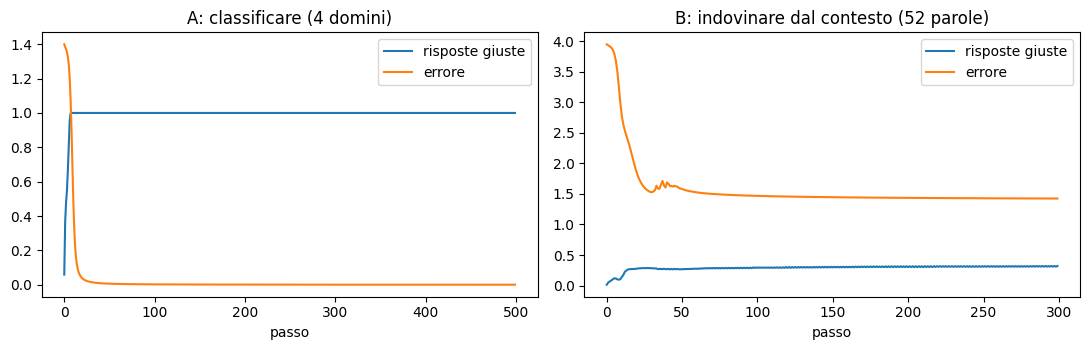

A: 1000 esempi, risposte giuste 1.00 (a caso: 0.25)
B: 3000 esempi, risposte giuste 0.32 (a caso: 0.02)


In [2]:
eta_cls, steps_cls = 5.0, 500
eta_cbow, steps_cbow = 20.0, 300
dim = 8


def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def init_params(n_in, n_hidden, n_out, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(scale=0.1, size=(n_in, n_hidden)),
            'W2': rng.normal(scale=0.1, size=(n_hidden, n_out)),
            'b2': np.zeros(n_out)}


def classification_data(corpus, index):
    X = np.zeros((len(corpus), len(index)))
    for n, (_, s) in enumerate(corpus):
        for w in s:
            X[n, index[w]] += 1 / len(s)
    y = np.array([domains.index(d) for d, _ in corpus])
    return X, y


def context_data(corpus, index):
    contexts, targets = [], []
    for _, s in corpus:
        for k, t in enumerate(s):
            contexts.append([w for j, w in enumerate(s) if j != k])
            targets.append(index[t])
    X = np.zeros((len(contexts), len(index)))
    for n, c in enumerate(contexts):
        for w in c:
            X[n, index[w]] += 1 / len(c)
    return X, np.array(targets)


def train(X, y, par, eta, steps, snapshots=()):
    par = {k: v.copy() for k, v in par.items()}
    Y = np.eye(par['b2'].size)[y]
    history, saved = [], {}
    for step in range(steps):
        if step in snapshots:
            saved[step] = par['W1'].copy()
        h = X @ par['W1']
        p = softmax(h @ par['W2'] + par['b2'])
        history.append({'loss': -np.log(p[np.arange(len(y)), y]).mean(),
                        'accuracy': (p.argmax(axis=1) == y).mean()})
        ds = (p - Y) / len(y)
        dh = ds @ par['W2'].T
        par['W2'] -= eta * h.T @ ds
        par['b2'] -= eta * ds.sum(axis=0)
        par['W1'] -= eta * X.T @ dh
    saved[steps] = par['W1'].copy()
    return par, pd.DataFrame(history), saved


X_cls, y_cls = classification_data(corpus, index)
X_cbow, y_cbow = context_data(corpus, index)

snapshots = (0, 5, 10, 20, 50, 100, 200, 300)
cls_par, cls_history, _ = train(X_cls, y_cls, init_params(V, dim, len(domains)), eta_cls, steps_cls)
cbow_par, cbow_history, cbow_saved = train(X_cbow, y_cbow, init_params(V, dim, V), eta_cbow, steps_cbow, snapshots)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, hist, name in zip(axes, [cls_history, cbow_history], ['A: classificare (4 domini)', 'B: indovinare dal contesto (52 parole)']):
    hist['accuracy'].plot(ax=ax, label='risposte giuste')
    hist['loss'].plot(ax=ax, label='errore')
    ax.set_title(name)
    ax.set_xlabel('passo')
    ax.legend()
plt.tight_layout()
plt.show()

print(f"A: {len(X_cls)} esempi, risposte giuste {cls_history['accuracy'].iloc[-1]:.2f} (a caso: {1 / len(domains):.2f})")
print(f"B: {len(X_cbow)} esempi, risposte giuste {cbow_history['accuracy'].iloc[-1]:.2f} (a caso: {1 / V:.2f})")

## Un momento di riflessione

- Il compito A arriva al 100%, il compito B no. Perché? Se conoscete le regole con cui sono generate le frasi, quale sarebbe la percentuale massima per il compito B?
- Nel compito A le etichette le abbiamo decise noi. Che cosa abbiamo già deciso, prima ancora di allenare la rete, su come devono essere raggruppate le parole?
- Nel compito B nessuno ha etichettato niente. Da dove viene la risposta giusta?
- Le due reti hanno lo stesso numero di dimensioni intermedie. Quanti parametri ha ciascuna? Da che cosa dipende la differenza?

## Le mappe

Proiettiamo i vettori nel piano con la PCA, come nei notebook precedenti. Il **colore** indica il dominio della parola, la **forma** il suo ruolo nella frase: cerchio per i soggetti, triangolo per i verbi, quadrato per gli oggetti. Queste informazioni le usiamo solo per leggere la mappa: la rete non le ha mai viste.

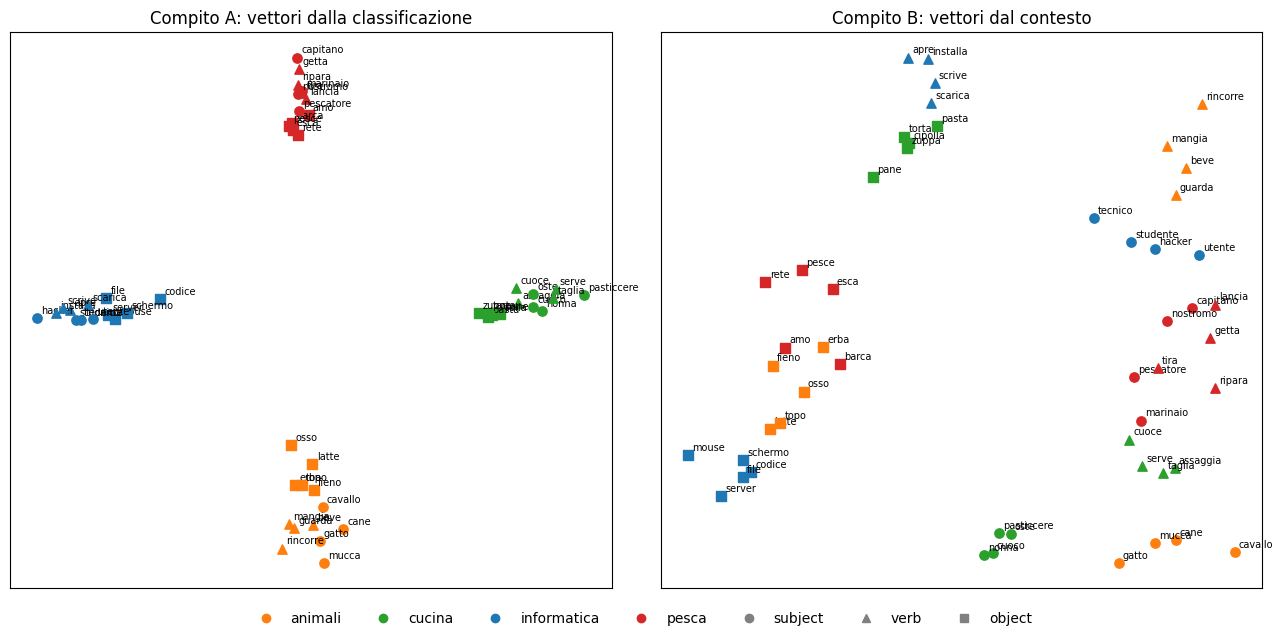

In [3]:
def pca2(W, fit=None):
    fit = np.arange(len(W)) if fit is None else fit
    mean = W[fit].mean(axis=0)
    _, _, Vt = np.linalg.svd(W[fit] - mean, full_matrices=False)
    return (W - mean) @ Vt[:2].T


def draw_map(ax, W, title, words=vocab, mark=None, grey=()):
    fit = [i for i, w in enumerate(words) if w not in grey]
    P = pca2(W, fit)
    for i, w in enumerate(words):
        c = 'lightgray' if w in grey else colors[domain_of[w]]
        ax.scatter(*P[i], color=c, marker=markers[role_of[w]], s=45, zorder=3)
        ax.annotate(w, P[i], fontsize=7, xytext=(3, 3), textcoords='offset points')
    if mark is not None:
        ax.scatter(*P[words.index(mark)], marker='*', s=320, facecolor='gold', edgecolor='black', zorder=4)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def add_legend(fig, grey=False):
    handles = [Line2D([], [], marker='o', color=c, linestyle='', label=d) for d, c in colors.items()]
    handles += [Line2D([], [], marker=m, color='gray', linestyle='', label=r) for r, m in markers.items()]
    if grey:
        handles.append(Line2D([], [], marker='o', color='lightgray', linestyle='', label='mai vista'))
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
draw_map(axes[0], cls_par['W1'], 'Compito A: vettori dalla classificazione')
draw_map(axes[1], cbow_par['W1'], 'Compito B: vettori dal contesto')
add_legend(fig)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Un momento di riflessione

- Nella mappa A, quante «zone» vedete? Che cosa hanno in comune le parole che finiscono nello stesso punto?
- *gatto* e *mangia* nella mappa A sono vicini o lontani? E nella mappa B? Che cosa dice la rete, nei due casi, sul rapporto tra un soggetto e un verbo?
- Nella mappa B, che cosa separa le parole oltre al dominio? Guardate le forme.
- Nessuna delle due reti ha mai ricevuto il ruolo grammaticale delle parole. Come è possibile che compaia nella mappa B?
- Dove sta *rete*? Aveva senso aspettarselo?

## I cluster di similarità

La mappa è una proiezione e può ingannare. Guardiamo allora le similarità direttamente: per ogni coppia di parole, il coseno tra i loro vettori. Riordiniamo righe e colonne con un clustering gerarchico, così le parole simili finiscono vicine e i blocchi diventano visibili. Rosso è molto simile, blu opposto.

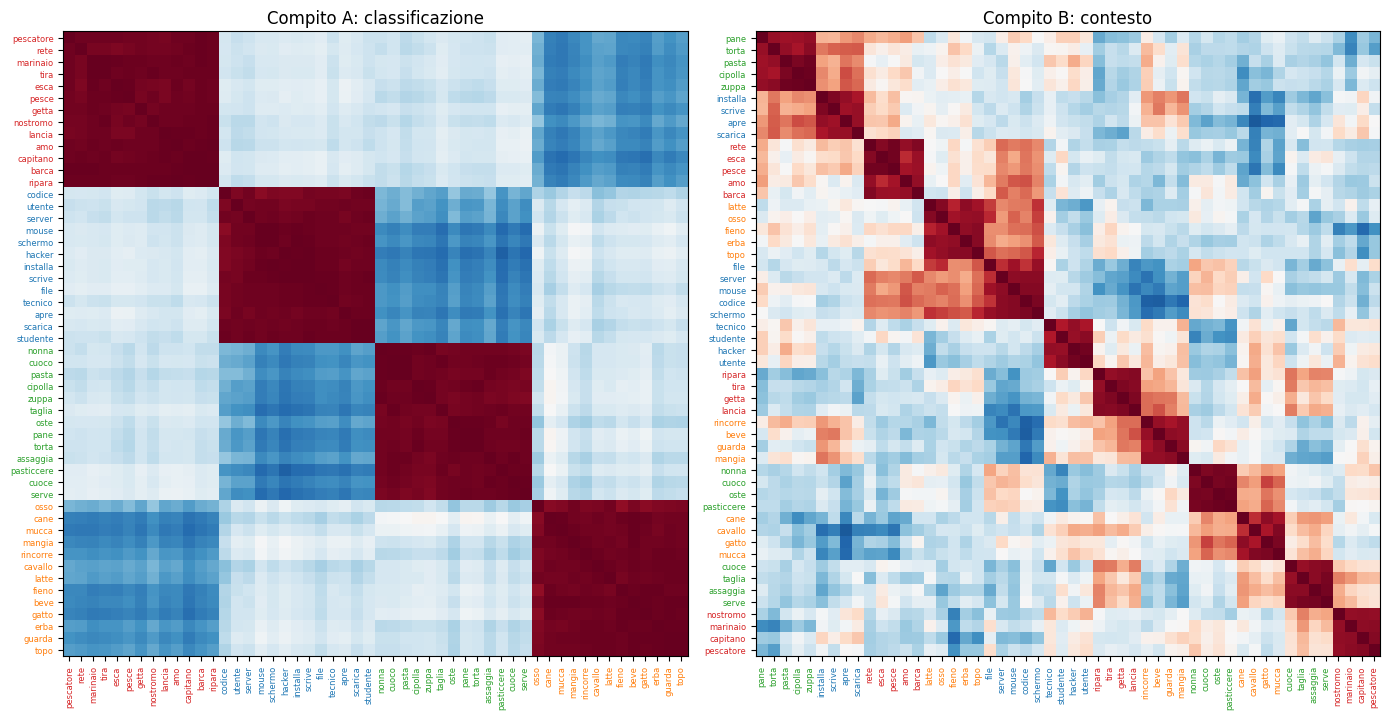

                         A: classificazione                       B: contesto
gatto             beve, guarda, fieno, topo       mucca, cane, cavallo, cuoco
mangia        beve, mucca, rincorre, guarda  guarda, beve, rincorre, installa
topo            guarda, erba, beve, cavallo          erba, fieno, osso, latte
cuoco        pasta, nonna, taglia, assaggia    pasticcere, oste, nonna, gatto
scarica        studente, scrive, file, apre     scrive, apre, installa, torta
rete     barca, ripara, capitano, pescatore           pesce, barca, esca, amo

Quota dei 3 vicini più prossimi che hanno lo stesso dominio / lo stesso ruolo:
                    stesso dominio  stesso ruolo
a caso                        0.24          0.32
A: classificazione            1.00          0.33
B: contesto                   0.99          1.00


In [4]:
def normalize(W):
    return W / np.linalg.norm(W, axis=1, keepdims=True)


def neighbors(W, word, words=vocab, k=4):
    s = normalize(W) @ normalize(W)[words.index(word)]
    return [words[j] for j in np.argsort(-s) if words[j] != word][:k]


def neighbor_quota(W, group, words=vocab, k=3):
    S = normalize(W) @ normalize(W).T
    np.fill_diagonal(S, -np.inf)
    hits = sum(group[words[j]] == group[w] for i, w in enumerate(words) for j in np.argsort(-S[i])[:k])
    return hits / (k * len(words))


def chance_quota(group, words=vocab):
    labels = [group[w] for w in words]
    return np.mean([(labels.count(l) - 1) / (len(words) - 1) for l in labels])


def draw_similarity(ax, W, title, words=vocab):
    S = normalize(W) @ normalize(W).T
    order = leaves_list(linkage(W, 'average', metric='cosine'))
    ax.imshow(S[order][:, order], cmap='RdBu_r', vmin=-1, vmax=1)
    labels = [words[i] for i in order]
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(labels, rotation=90, fontsize=6)
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(labels, fontsize=6)
    for tick, w in zip(list(ax.get_xticklabels()) + list(ax.get_yticklabels()), labels + labels):
        tick.set_color(colors[domain_of[w]])
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
draw_similarity(axes[0], cls_par['W1'], 'Compito A: classificazione')
draw_similarity(axes[1], cbow_par['W1'], 'Compito B: contesto')
plt.tight_layout()
plt.show()

probe = ['gatto', 'mangia', 'topo', 'cuoco', 'scarica', 'rete']
print(pd.DataFrame({'A: classificazione': [', '.join(neighbors(cls_par['W1'], w)) for w in probe],
                    'B: contesto': [', '.join(neighbors(cbow_par['W1'], w)) for w in probe]}, index=probe).to_string())

print('\nQuota dei 3 vicini più prossimi che hanno lo stesso dominio / lo stesso ruolo:')
role_chance = chance_quota(role_of)
quota = pd.DataFrame({
    'stesso dominio': [chance_quota(domain_of), neighbor_quota(cls_par['W1'], domain_of), neighbor_quota(cbow_par['W1'], domain_of)],
    'stesso ruolo': [role_chance, neighbor_quota(cls_par['W1'], role_of), neighbor_quota(cbow_par['W1'], role_of)]},
    index=['a caso', 'A: classificazione', 'B: contesto'])
print(quota.round(2).to_string())

## Un momento di riflessione

- Nella matrice A, che cosa si vede al posto dei 52 punti? Quante parole sono praticamente identiche?
- Nella matrice B, quali blocchi si formano? Sono più piccoli o più grandi di quelli di A? Quali parole stanno insieme che in A non lo erano?
- Guardate i vicini di *gatto* nei due casi. Quale lista direste «più giusta»? Rispetto a che cosa?
- *scarica* ha vicini sensati in B. Che cosa dobbiamo concludere sulla relazione tra *scarica* e le altre parole di informatica?
- La classificazione conserva il dominio, il contesto conserva il dominio e il ruolo. Perché la classificazione non può conservare il ruolo?

## Perché contesti simili danno vettori simili

Finora abbiamo solo osservato. Proviamo a capire il meccanismo, in tre passi.

Il **profilo di contesto** di una parola è la riga della sua tabella di co-occorrenza: per ogni altra parola del vocabolario, in quante frasi compaiono insieme. Due parole hanno profili simili se compaiono con le stesse parole, anche se non compaiono mai l'una con l'altra.

Confrontiamo, per ogni coppia di parole, la similarità dei profili con la similarità dei vettori appresi.

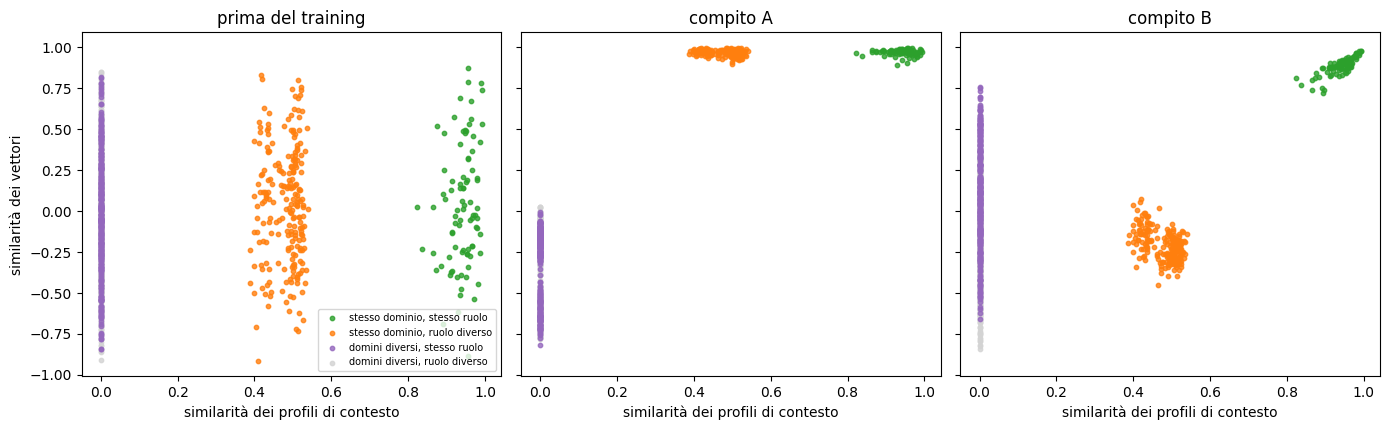

                frasi insieme  sim. profili  sim. vettori A  sim. vettori B
gatto - cane                0          0.97            0.98            0.89
gatto - mucca               0          0.96            0.98            0.94
gatto - topo               11          0.52            0.98           -0.20
gatto - mangia             11          0.42            0.96           -0.14
gatto - cuoco               0          0.00           -0.11            0.68


In [5]:
cooc = np.zeros((V, V))
for _, s in corpus:
    for a in s:
        for b in s:
            if a != b:
                cooc[index[a], index[b]] += 1


def cosine_pairs(M):
    S = normalize(M) @ normalize(M).T
    i, j = np.triu_indices(len(M), k=1)
    return S[i, j]


i_pairs, j_pairs = np.triu_indices(V, k=1)
same_domain = np.array([domain_of[vocab[i]] == domain_of[vocab[j]] for i, j in zip(i_pairs, j_pairs)])
same_role = np.array([role_of[vocab[i]] == role_of[vocab[j]] for i, j in zip(i_pairs, j_pairs)])
kind = np.where(same_domain & same_role, 0, np.where(same_domain, 1, np.where(same_role, 2, 3)))
kind_style = [('stesso dominio, stesso ruolo', 'tab:green'), ('stesso dominio, ruolo diverso', 'tab:orange'),
              ('domini diversi, stesso ruolo', 'tab:purple'), ('domini diversi, ruolo diverso', 'lightgray')]

profile_sim = cosine_pairs(cooc)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, W, title in zip(axes, [init_params(V, dim, V)['W1'], cls_par['W1'], cbow_par['W1']],
                        ['prima del training', 'compito A', 'compito B']):
    sim = cosine_pairs(W)
    for k, (label, c) in enumerate(kind_style):
        ax.scatter(profile_sim[kind == k], sim[kind == k], s=10, color=c, label=label, alpha=0.8, zorder=(5 if k == 2 else 3))
    ax.set_title(title)
    ax.set_xlabel('similarità dei profili di contesto')
axes[0].set_ylabel('similarità dei vettori')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

pairs = [('gatto', 'cane'), ('gatto', 'mucca'), ('gatto', 'topo'), ('gatto', 'mangia'), ('gatto', 'cuoco')]
Wn_cls, Wn_cbow = normalize(cls_par['W1']), normalize(cbow_par['W1'])
Pn = normalize(cooc)
print(pd.DataFrame({
    'frasi insieme': [int(cooc[index[a], index[b]]) for a, b in pairs],
    'sim. profili': [Pn[index[a]] @ Pn[index[b]] for a, b in pairs],
    'sim. vettori A': [Wn_cls[index[a]] @ Wn_cls[index[b]] for a, b in pairs],
    'sim. vettori B': [Wn_cbow[index[a]] @ Wn_cbow[index[b]] for a, b in pairs]},
    index=[f'{a} - {b}' for a, b in pairs]).round(2).to_string())

## Un momento di riflessione

- Prima del training la similarità tra i vettori non ha nessun rapporto con i profili. Dopo il training del compito B sì. Che cosa è successo nel mezzo?
- *gatto* e *cane* non compaiono mai nella stessa frase, eppure i loro profili sono simili. Perché?
- *gatto* e *topo* compaiono insieme in molte frasi. Hanno vettori simili? Compaiono nello stesso modo?
- Che cosa misura davvero la similarità tra due vettori: quanto due parole stanno insieme, o quanto sono sostituibili l'una con l'altra?
- Nel grafico A i punti si dispongono in modo diverso rispetto a B. Che cosa guardano i vettori del compito A, se non il contesto?
- Le coppie viola, come *gatto* e *cuoco*, non hanno nessuna parola in comune nel contesto, eppure nel compito B i loro vettori sono abbastanza simili. Che cosa hanno in comune, se non le stesse parole? Un profilo di contesto che conta le parole esatte lo vedrebbe?

## Come lo impara la rete

Ogni passo di training sposta la riga di $W_1$ di una parola $w$ di una quantità che dipende solo dagli esempi in cui $w$ è nel contesto. All'inizio, quando le probabilità sono ancora tutte uguali, la spinta ha una forma molto semplice:

$$\Delta W_1[w] \;\approx\; \eta \sum_{t} \text{cooc}(w, t)\; W_2[:, t]$$

Il vettore di $w$ viene spinto verso i vettori di uscita $W_2[:, t]$ delle parole $t$ che compaiono con lui, ciascuna pesata per quante volte compare. Due parole con lo stesso profilo di contesto ricevono la stessa spinta, a ogni passo.

Verifichiamo la formula sul primo passo, poi guardiamo i coseni durante tutto l'allenamento.

Coseno tra la spinta vera e la formula, sulle 52 parole: media 0.941, minimo 0.716
Coseno tra le spinte del primo passo:
  gatto - cane: 0.93
  gatto - mucca: 0.92
  gatto - topo: 0.58
  gatto - mangia: 0.84
  gatto - cuoco: -0.17


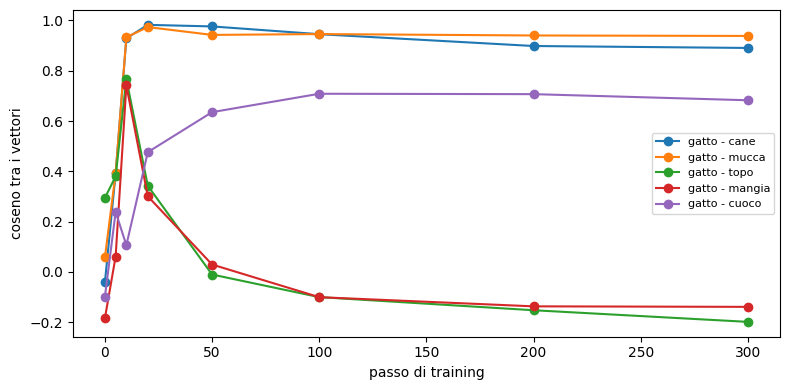

Lunghezza media dei vettori: prima 0.28, dopo 3.25


In [6]:
par0 = init_params(V, dim, V)
Y0 = np.eye(V)[y_cbow]
p0 = softmax(X_cbow @ par0['W1'] @ par0['W2'] + par0['b2'])
push = -eta_cbow * X_cbow.T @ (((p0 - Y0) / len(y_cbow)) @ par0['W2'].T)
formula = eta_cbow / len(y_cbow) * (cooc / 2) @ par0['W2'].T

cos_rows = (normalize(push) * normalize(formula)).sum(axis=1)
print(f'Coseno tra la spinta vera e la formula, sulle 52 parole: media {cos_rows.mean():.3f}, minimo {cos_rows.min():.3f}')
Pu = normalize(push)
print('Coseno tra le spinte del primo passo:')
for a, b in pairs:
    print(f'  {a} - {b}: {Pu[index[a]] @ Pu[index[b]]:.2f}')

steps_seen = sorted(cbow_saved)
fig, ax = plt.subplots(figsize=(8, 4))
for a, b in pairs:
    ax.plot(steps_seen, [normalize(cbow_saved[s])[index[a]] @ normalize(cbow_saved[s])[index[b]] for s in steps_seen],
            marker='o', label=f'{a} - {b}')
ax.set_xlabel('passo di training')
ax.set_ylabel('coseno tra i vettori')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

norms = {s: np.linalg.norm(cbow_saved[s], axis=1).mean() for s in (0, 300)}
print(f'Lunghezza media dei vettori: prima {norms[0]:.2f}, dopo {norms[300]:.2f}')

## Un momento di riflessione

- La formula riproduce la spinta vera? Perché è vera solo all'inizio e non lungo tutto il training?
- Perché due parole con gli stessi vicini ricevono le stesse spinte? Che ruolo ha la tabella di co-occorrenza?
- Prima del training i vettori di *gatto* e *cane* sono casuali. Che cosa li ha resi simili: il fatto di essere cani e gatti, o il fatto di stare in frasi simili?
- Quanto sono diventati lunghi i vettori rispetto a quelli iniziali? Che cosa resta, a fine training, della scelta casuale di partenza?
- Nel grafico, quali coppie salgono e quali no? Perché la coppia *gatto - mangia* non sale come *gatto - cane*?

## Una prova: due parole che non si incontrano mai

Mettiamo alla prova l'idea con un esperimento costruito apposta. Prendiamo il corpus e, in metà delle frasi con *gatto*, sostituiamo la parola con una nuova, *micio*. Le due parole sono intercambiabili, ma non compaiono mai nella stessa frase: tutto quello che la rete può sapere di *micio* viene dal suo contesto.

Frasi con micio: 29, con gatto: 33, con tutti e due: 0
               frasi insieme  sim. vettori A  sim. vettori B
micio - gatto              0            0.95            0.80
micio - cane               0            0.97            0.83
micio - topo               4            0.97           -0.06
micio - cuoco              0           -0.21            0.10

Vicini di micio nel compito B: mucca, cavallo, cane, gatto, serve


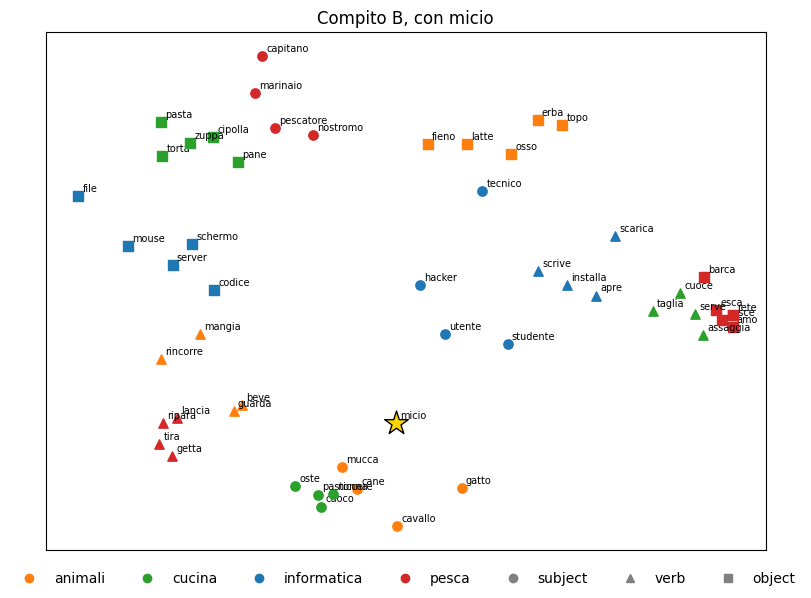

In [7]:
rng = np.random.default_rng(7)
corpus_syn = [(d, ['micio' if w == 'gatto' and rng.random() < 0.5 else w for w in s]) for d, s in corpus]
vocab_syn = vocab + ['micio']
index_syn = {w: i for i, w in enumerate(vocab_syn)}
domain_of['micio'], role_of['micio'] = 'animali', 'subject'

n_both = sum('micio' in s and 'gatto' in s for _, s in corpus_syn)
print(f"Frasi con micio: {sum('micio' in s for _, s in corpus_syn)}, con gatto: {sum('gatto' in s for _, s in corpus_syn)}, con tutti e due: {n_both}")

X_syn, y_syn = context_data(corpus_syn, index_syn)
syn_cbow, _, _ = train(X_syn, y_syn, init_params(len(vocab_syn), dim, len(vocab_syn)), eta_cbow, steps_cbow)
X_syn_cls, y_syn_cls = classification_data(corpus_syn, index_syn)
syn_cls, _, _ = train(X_syn_cls, y_syn_cls, init_params(len(vocab_syn), dim, len(domains)), eta_cls, steps_cls)

pairs_syn = [('micio', 'gatto'), ('micio', 'cane'), ('micio', 'topo'), ('micio', 'cuoco')]
rows = {}
for name, W in [('sim. vettori A', syn_cls['W1']), ('sim. vettori B', syn_cbow['W1'])]:
    Wn = normalize(W)
    rows[name] = [Wn[index_syn[a]] @ Wn[index_syn[b]] for a, b in pairs_syn]
rows = {'frasi insieme': [sum(a in s and b in s for _, s in corpus_syn) for a, b in pairs_syn], **rows}
print(pd.DataFrame(rows, index=[f'{a} - {b}' for a, b in pairs_syn]).round(2).to_string())
print('\nVicini di micio nel compito B:', ', '.join(neighbors(syn_cbow['W1'], 'micio', vocab_syn, k=5)))

fig, ax = plt.subplots(figsize=(7.5, 6))
draw_map(ax, syn_cbow['W1'], 'Compito B, con micio', words=vocab_syn, mark='micio')
add_legend(fig)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Un momento di riflessione

- *micio* e *gatto* non compaiono mai insieme. Quanto sono simili i loro vettori nel compito B? E nel compito A?
- Rispetto a *micio*, *cane* è più simile o meno simile di *gatto*? E *topo*, che con *micio* compare spesso?
- Che cosa sapeva la rete di *micio*, prima di vederlo nelle frasi? Da dove ha preso il suo significato?
- Se *micio* comparisse in una sola frase, che cosa possiamo aspettarci dal suo vettore? Quanti esempi servono per «fidarsi» di una parola?
- In che senso questa è una definizione di sinonimia? Dove potrebbe sbagliare?

---

# Stesso modello, altri dati

Da qui il modello e la procedura restano uguali, quelli del compito B. Cambiamo solo il corpus.

## Quanti dati

Alleniamo lo stesso modello su corpora di dimensione crescente, sempre nello stesso mondo. Per ciascuna dimensione ripetiamo l'esperimento cinque volte, con corpora e inizializzazioni diversi, e misuriamo la quota di vicini dello stesso dominio.

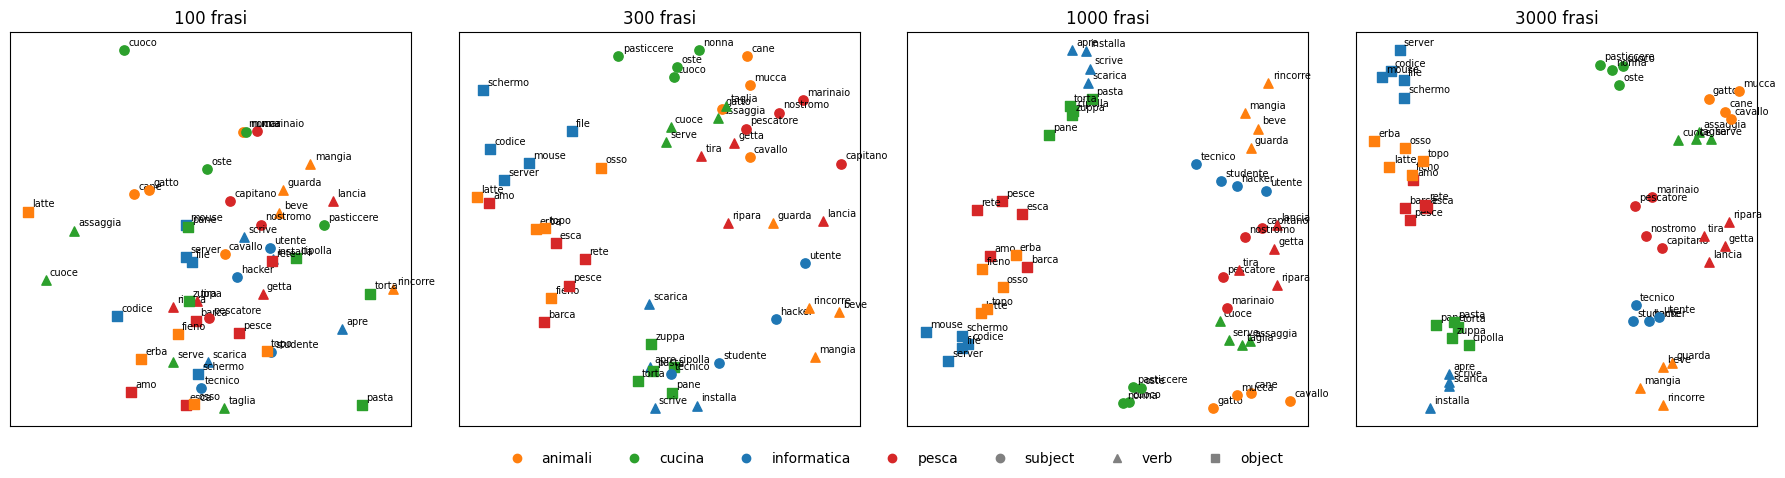

            stesso dominio  stesso ruolo
100 frasi             0.38          0.57
300 frasi             0.91          0.94
1000 frasi            1.00          1.00
3000 frasi            1.00          1.00
a caso: dominio 0.24, ruolo 0.32


In [8]:
sizes = [100, 300, 1000, 3000]
fig, axes = plt.subplots(1, len(sizes), figsize=(18, 4.8))
results = []
for ax, n in zip(axes, sizes):
    quotas = []
    for seed in range(5):
        X, y = context_data(generate(n, seed), index)
        par, _, _ = train(X, y, init_params(V, dim, V, seed), eta_cbow, steps_cbow)
        quotas.append((neighbor_quota(par['W1'], domain_of), neighbor_quota(par['W1'], role_of)))
        if seed == 0:
            draw_map(ax, par['W1'], f'{n} frasi')
    results.append(np.mean(quotas, axis=0))
add_legend(fig)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

print(pd.DataFrame(results, index=[f'{n} frasi' for n in sizes], columns=['stesso dominio', 'stesso ruolo']).round(2).to_string())
print(f'a caso: dominio {chance_quota(domain_of):.2f}, ruolo {chance_quota(role_of):.2f}')

## Un momento di riflessione

- Con 100 frasi la mappa è leggibile? Quante volte, in media, compare ciascuna parola?
- La qualità cresce sempre con i dati o a un certo punto si ferma? Che cosa ci dice questo su quanti dati servono in un mondo così semplice?
- In un corpus vero il vocabolario ha decine di migliaia di parole e molte sono rare. Che cosa succede alle parole che compaiono poche volte?
- Le parole vicine a una parola rara sono affidabili? Come ve ne accorgereste?

## Quali dati

Ora togliamo interi argomenti. Il vocabolario resta di 52 parole, ma il corpus parla solo di animali e di cucina. Le parole di informatica e di pesca esistono nel modello, e non le ha mai incontrate.

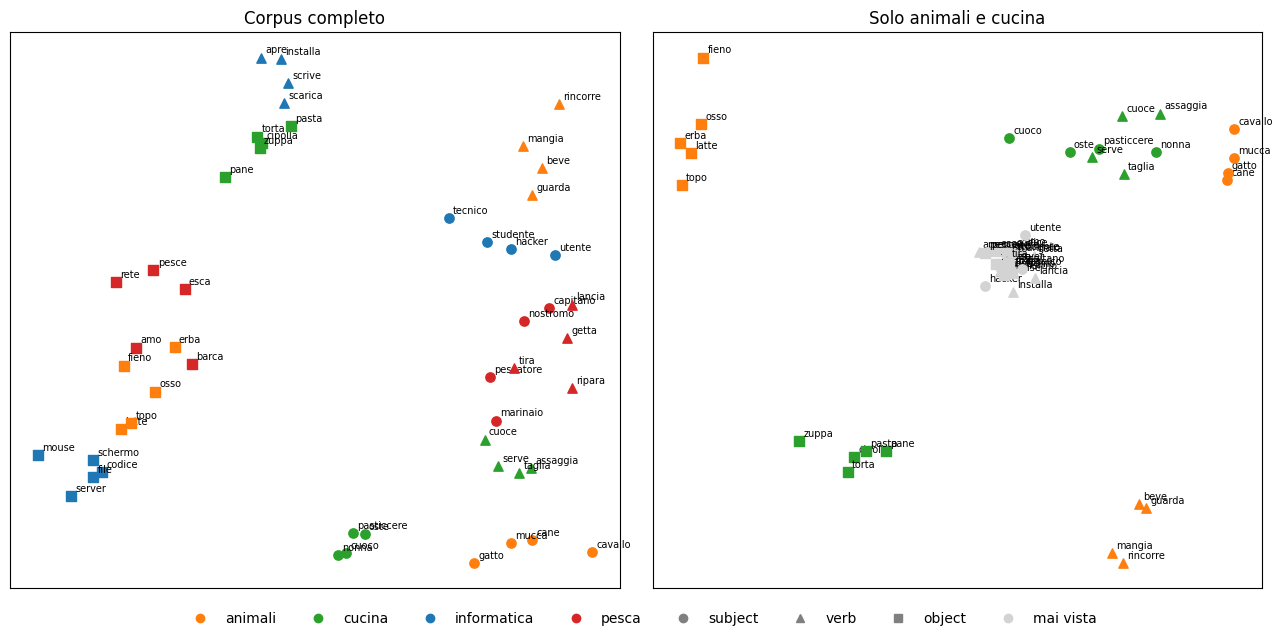

                        corpus completo              solo animali e cucina
gatto       mucca, cane, cavallo, cuoco      cane, cavallo, mucca, tecnico
cuoco    pasticcere, oste, nonna, gatto  pasticcere, oste, nonna, marinaio
scarica   scrive, apre, installa, torta      codice, esca, serve, marinaio
rete            pesce, barca, esca, amo       tecnico, barca, ripara, file


In [9]:
active = ['animali', 'cucina']
corpus_part = generate(1000, seed=0, active=active)
X_part, y_part = context_data(corpus_part, index)
part_par, _, _ = train(X_part, y_part, init_params(V, dim, V), eta_cbow, steps_cbow)
seen = {w for _, s in corpus_part for w in s}
unseen = [w for w in vocab if w not in seen]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
draw_map(axes[0], cbow_par['W1'], 'Corpus completo')
draw_map(axes[1], part_par['W1'], 'Solo animali e cucina', grey=unseen)
add_legend(fig, grey=True)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

probe = ['gatto', 'cuoco', 'scarica', 'rete']
print(pd.DataFrame({'corpus completo': [', '.join(neighbors(cbow_par['W1'], w)) for w in probe],
                    'solo animali e cucina': [', '.join(neighbors(part_par['W1'], w)) for w in probe]}, index=probe).to_string())

## Un momento di riflessione

- Dove stanno, nella seconda mappa, le parole mai viste? Hanno un significato per il modello?
- Un modello allenato solo su animali e cucina riceve la frase *utente scarica file*. Che cosa può dire? Che cosa ci dà il suo vettore per *scarica*?
- I vicini di *gatto* sono cambiati rispetto al corpus completo? Che cosa ci dice sulla dipendenza del significato dall'insieme degli altri dati?
- Un corpus ha sempre dei confini: epoca, genere, autore. Che cosa possiamo dire del significato appreso da un corpus quando lo usiamo su testi di fuori?

## Quando cambia il significato

Torniamo a *rete*. Nel corpus «vecchio» compare solo in frasi di pesca. Nel corpus «nuovo» compare solo in frasi di informatica. Tra i due estremi, corpora in cui una parte degli usi è passata dalla pesca all'informatica: 25%, 50%, 75%.

Tutto il resto del mondo non cambia, e *rete* ha sempre la stessa frequenza. Ogni corpus ha 2000 frasi, ripetute con cinque inizializzazioni diverse.

Alleniamo un modello per ciascun corpus. Gli spazi che escono sono ruotati l'uno rispetto all'altro, quindi le mappe non si possono sovrapporre. Per misurare lo spostamento usiamo una quantità che dalla rotazione non dipende: la similarità di *rete*, che è un oggetto, con il centro degli oggetti di pesca e con il centro degli oggetti di informatica.

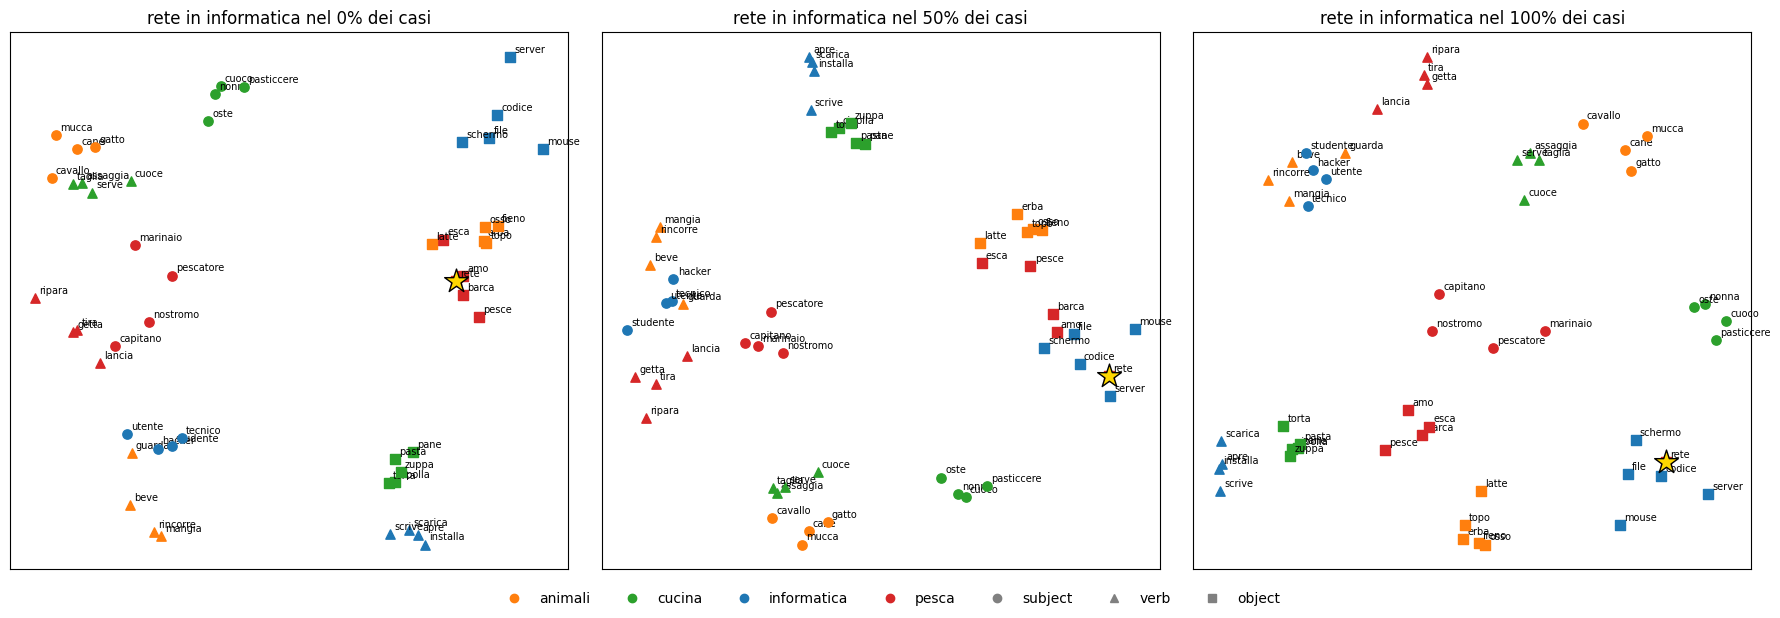

                                        vicini di rete
0% informatica        pesce, barca, esca, amo, schermo
25% informatica        barca, pesce, esca, amo, codice
50% informatica    barca, schermo, codice, server, amo
75% informatica   schermo, codice, mouse, server, esca
100% informatica  codice, schermo, server, mouse, file


In [10]:
shares = [0, 0.25, 0.5, 0.75, 1.0]
shift_models = {}
for f in shares:
    for seed in range(5):
        X, y = context_data(generate(2000, seed, new_use=f), index)
        par, _, _ = train(X, y, init_params(V, dim, V, seed), eta_cbow, steps_cbow)
        shift_models[(f, seed)] = par['W1']

fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, f in zip(axes, [0, 0.5, 1.0]):
    draw_map(ax, shift_models[(f, 0)], f'rete in informatica nel {int(f * 100)}% dei casi', mark='rete')
add_legend(fig)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

print(pd.DataFrame({f'{int(f * 100)}% informatica': [', '.join(neighbors(shift_models[(f, 0)], 'rete', k=5))] for f in shares},
                   index=['vicini di rete']).T.to_string())

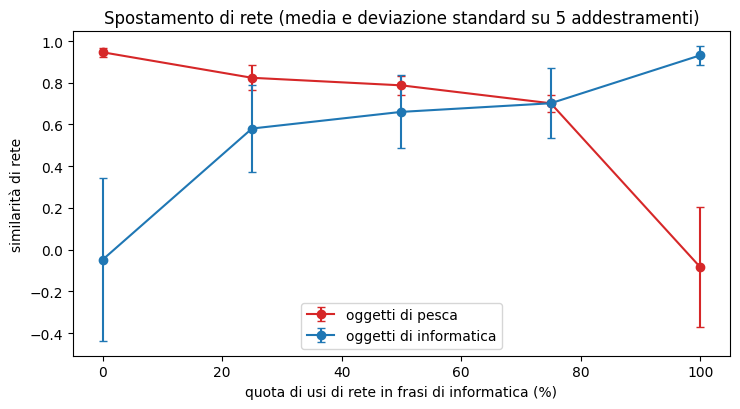

In [11]:
def domain_similarity(W, word, domain):
    Wn = normalize(W)
    members = [index[w] for w in vocab if domain_of[w] == domain and role_of[w] == role_of[word] and w != word]
    center = Wn[members].mean(axis=0)
    return Wn[index[word]] @ center / np.linalg.norm(center)


track = np.array([[[domain_similarity(shift_models[(f, s)], 'rete', d) for d in ['pesca', 'informatica']]
                   for s in range(5)] for f in shares])
mean, std = track.mean(axis=1), track.std(axis=1)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = [f * 100 for f in shares]
for k, (d, c) in enumerate([('pesca', 'tab:red'), ('informatica', 'tab:blue')]):
    ax.errorbar(x, mean[:, k], yerr=std[:, k], marker='o', color=c, capsize=3, label=f'oggetti di {d}')
ax.set_xlabel('quota di usi di rete in frasi di informatica (%)')
ax.set_ylabel('similarità di rete')
ax.set_title('Spostamento di rete (media e deviazione standard su 5 addestramenti)')
ax.legend()
plt.tight_layout()
plt.show()

## Un momento di riflessione

- Nelle tre mappe *rete* si muove? Verso dove? Le altre parole restano dove erano? Gli assi della PCA sono gli stessi nelle tre mappe?
- Nel corpus al 50% *rete* sta in mezzo. È una nuova parola con un significato nuovo, o la somma dei due? Che cosa è un vettore «in mezzo»?
- Lo spostamento è graduale o a salti? Quanti usi nuovi bastano per avvicinare *rete* all'informatica? Che cosa succede ai vicini nei passaggi intermedi?
- Il modello non ha nessun concetto di «prima» e «dopo»: ha solo corpora diversi. Come si potrebbe costruire, con questi strumenti, la storia di una parola attraverso gli anni?
- Il vettore di *rete* a 50% dice che la parola ha due significati, o che il modello ne ha uno solo, medio? Che cosa servirebbe per distinguerli?
- Per fidarci di uno spostamento serve confrontare più addestramenti. Perché? Che cosa indicano le barre?

## Che cosa viene dopo

Usiamo il modello del compito B, allenato sul corpus iniziale, in modo diverso. Gli diamo l'inizio di una frase, una o due parole, e guardiamo la probabilità che assegna a ciascuna delle 52 parole del vocabolario per la parola che segue.

Nella cella qui sotto basta cambiare il testo di `prompt`.

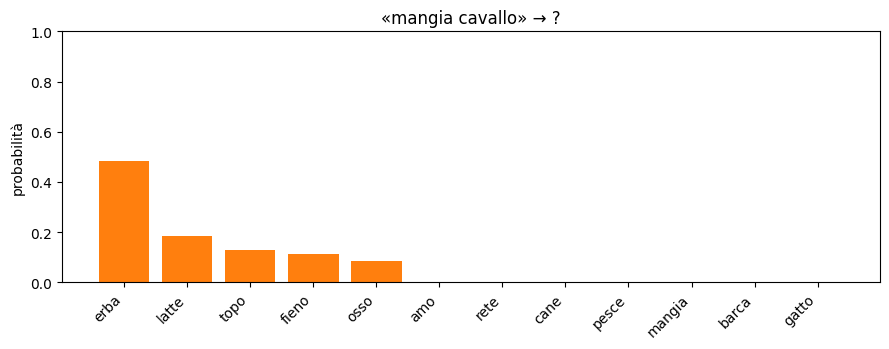

Probabilità per dominio: animali 1.00, cucina 0.00, informatica 0.00, pesca 0.00
Probabilità per ruolo:   subject 0.00, verb 0.00, object 1.00

Probabilità totale delle prime 5 parole: 1.00


In [23]:
prompt = 'mangia cavallo'

prompt_words = prompt.lower().split()
unknown = [w for w in prompt_words if w not in index]
if unknown:
    print('Parole fuori dal vocabolario:', unknown)
else:
    x = np.zeros(V)
    for w in prompt_words:
        x[index[w]] += 1 / len(prompt_words)
    p = softmax(x @ cbow_par['W1'] @ cbow_par['W2'] + cbow_par['b2'])

    top = np.argsort(-p)[:12]
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(range(len(top)), p[top], color=[colors[domain_of[vocab[j]]] for j in top])
    ax.set_xticks(range(len(top)))
    ax.set_xticklabels([vocab[j] for j in top], rotation=45, ha='right')
    ax.set_ylabel('probabilità')
    ax.set_ylim(0, 1)
    ax.set_title(f'«{prompt}» → ?')
    plt.tight_layout()
    plt.show()

    print('Probabilità per dominio:', ', '.join(f"{d} {sum(p[index[w]] for w in vocab if domain_of[w] == d):.2f}" for d in domains))
    print('Probabilità per ruolo:  ', ', '.join(f"{r} {sum(p[index[w]] for w in vocab if role_of[w] == r):.2f}" for r in markers))
    print(f'\nProbabilità totale delle prime 5 parole: {np.sort(p)[::-1][:5].sum():.2f}')

## Un momento di riflessione

- Con *gatto mangia*, quali parole hanno probabilità alta? Quante sono? Sono quelle che vi aspettate?
- La somma delle probabilità su tutto il vocabolario fa sempre 1. Che cosa vuol dire quando è distribuita su cinque parole, e quando è concentrata su una sola?
- Provate *cuoco taglia*, *utente scarica*, *pescatore getta*. Come cambia la distribuzione? Perché *rete* compare tra le risposte probabili solo in alcuni casi?
- Provate un prompt con parole di domini diversi, come *gatto scarica*. Che cosa risponde il modello? Esiste una risposta giusta?
- Provate una sola parola, come *utente*. Che cosa è cambiato rispetto al prompt di due parole? Quali ruoli hanno probabilità?
- Confrontate *gatto mangia* con *mangia gatto*. Il modello ha notato la differenza? Che cosa ci dice su come usa le parole del prompt?
- Provate a ripetere una parola, come *gatto gatto*, o a darne tre. Che cosa succede? Perché?
- Il modello assegna probabilità anche a frasi che non ha mai visto nel corpus. Da dove le ricava?